## Dataset Information

**Dataset:** Bank Customer Churn Dataset

**Source:** Kaggle

**Dataset URL:**
https://www.kaggle.com/datasets/gauravtopre/bank-customer-churn-dataset

**Total Records:** 10,000

**Total Columns:** 12

**Target Variable:** churn

### How to Run This Notebook

1. Download the Bank Customer Churn Dataset from Kaggle.
2. Open this notebook in Google Colab.
3. Run the Import Libraries section.
4. Upload the CSV when prompted.
5. Execute the notebook cells in order.

### Project Scope

This project demonstrates exploratory data analysis,
customer churn prediction, model comparison,
cross-validation, threshold tuning and model
interpretation using Python and Scikit-learn.

# Bank Customer Churn Prediction Using Machine Learning

## Project Objective
To analyze bank customer data and develop a machine
learning model that predicts whether a customer is
likely to leave the bank.

## Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Dataset
Bank Customer Churn Prediction (Kaggle)

## Import Required Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Load the Bank Customer Churn Dataset

In [2]:
# Upload dataset from your computer
from google.colab import files

uploaded = files.upload()



Saving Bank Customer Churn Prediction.csv to Bank Customer Churn Prediction.csv


In [3]:
# Load the Bank Customer Churn dataset
df = pd.read_csv("Bank Customer Churn Prediction.csv")

# Display the first 5 rows
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

print("Total Customers:", df.shape[0])
print("Total Features/Columns:", df.shape[1])

Dataset Shape: (10000, 12)
Total Customers: 10000
Total Features/Columns: 12


## Understanding the Dataset

In [5]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [6]:
# Check missing values in each column
df.isnull().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


## Exploratory Data Analysis (EDA)

### 1. Customer Churn Distribution

In [7]:
# Count customers who stayed and left the bank
df['churn'].value_counts()

,count
churn,
0,7963
1,2037


### 2. Visualization of Customer Churn Distribution

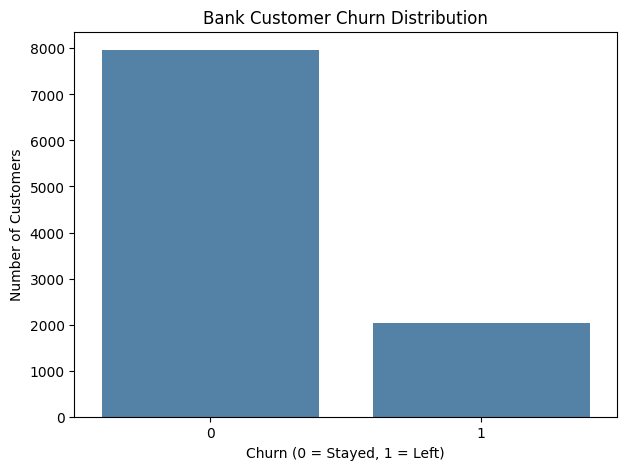

In [8]:
# Set the figure size
plt.figure(figsize=(7, 5))

# Create a bar chart
sns.countplot(x='churn', data=df, color='steelblue')

# Add chart title and labels
plt.title('Bank Customer Churn Distribution')
plt.xlabel('Churn (0 = Stayed, 1 = Left)')
plt.ylabel('Number of Customers')

# Display the chart
plt.show()

### 3. Customer Churn Analysis by Gender

gender
Female    25.07
Male      16.46
Name: churn, dtype: float64


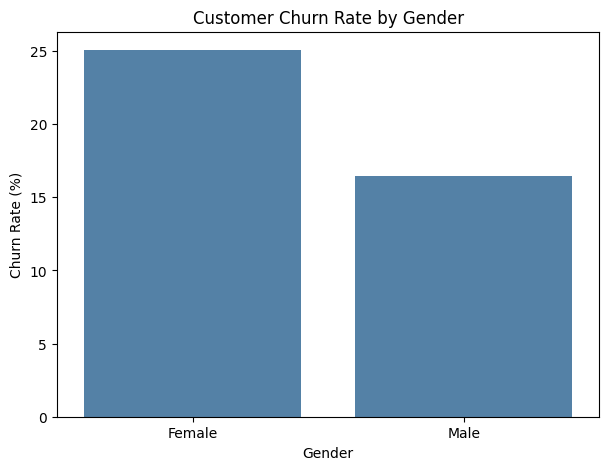

In [9]:
# Calculate churn rate by gender
gender_churn = df.groupby('gender')['churn'].mean() * 100

# Display churn percentages
print(gender_churn.round(2))

# Create visualization
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_churn.index,
    y=gender_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')

plt.show()

### 4. Customer Churn Analysis by Age Group

age_group
Under 30     7.56
30-39       10.88
40-49       30.79
50-59       56.04
60+         27.95
Name: churn, dtype: float64


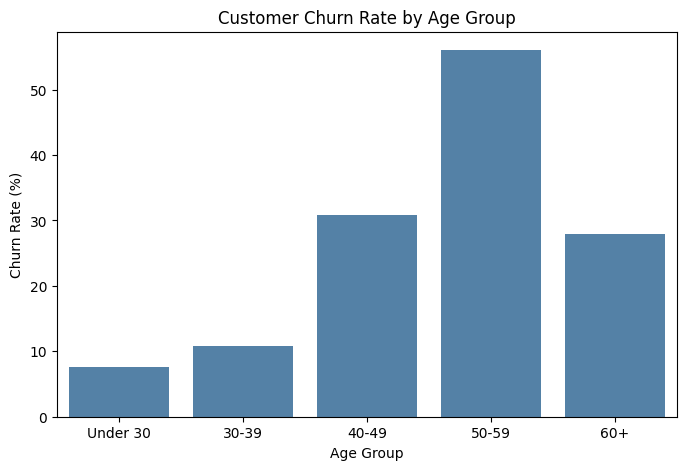

In [10]:
# Create customer age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 30, 40, 50, 60, float('inf')],
    labels=['Under 30', '30-39', '40-49', '50-59', '60+'],
    right=False
)

# Calculate churn rate for each age group
age_churn = df.groupby('age_group', observed=True)['churn'].mean() * 100

# Display churn percentages
print(age_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_churn.index,
    y=age_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')

plt.show()

### 5. Customer Churn Analysis by Geography

country
France     16.15
Germany    32.44
Spain      16.67
Name: churn, dtype: float64


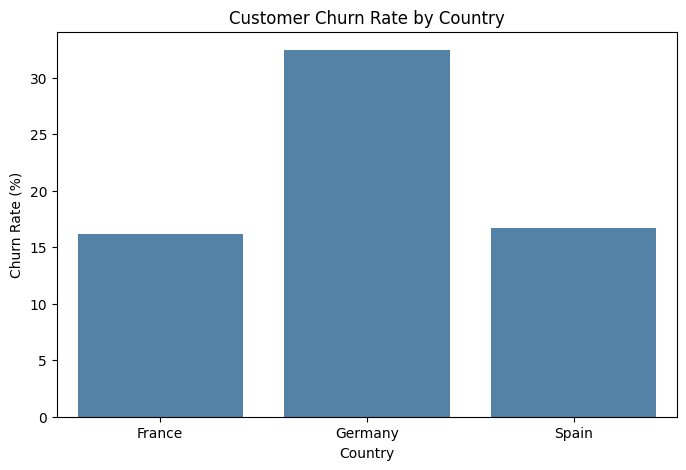

In [11]:
# Calculate churn rate by country
country_churn = df.groupby('country')['churn'].mean() * 100

# Display churn percentages
print(country_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=country_churn.index,
    y=country_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Country')
plt.xlabel('Country')
plt.ylabel('Churn Rate (%)')

plt.show()

### 6. Customer Churn Analysis by Account Balance

balance_group
Zero Balance    13.82
Up to 100k      20.58
Above 100k      25.23
Name: churn, dtype: float64


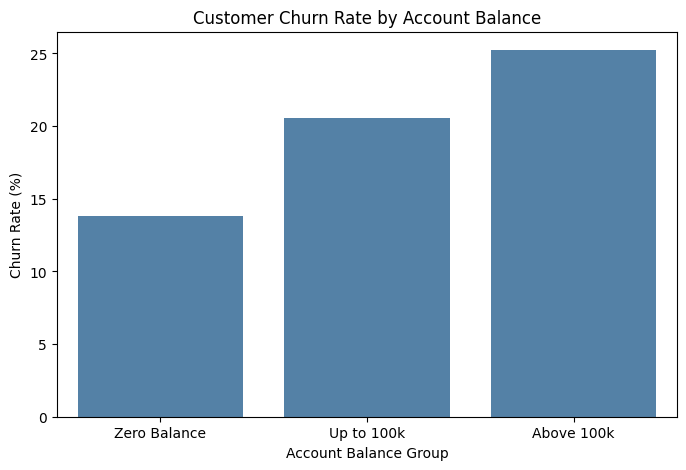

In [12]:
# Create account balance groups
df['balance_group'] = pd.cut(
    df['balance'],
    bins=[-1, 0, 100000, float('inf')],
    labels=['Zero Balance', 'Up to 100k', 'Above 100k']
)

# Calculate churn rate by balance group
balance_churn = df.groupby(
    'balance_group', observed=True
)['churn'].mean() * 100

# Display churn percentages
print(balance_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=balance_churn.index,
    y=balance_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Account Balance')
plt.xlabel('Account Balance Group')
plt.ylabel('Churn Rate (%)')

plt.show()

### 7. Customer Churn Analysis by Number of Bank Products

products_number
1     27.71
2      7.58
3     82.71
4    100.00
Name: churn, dtype: float64


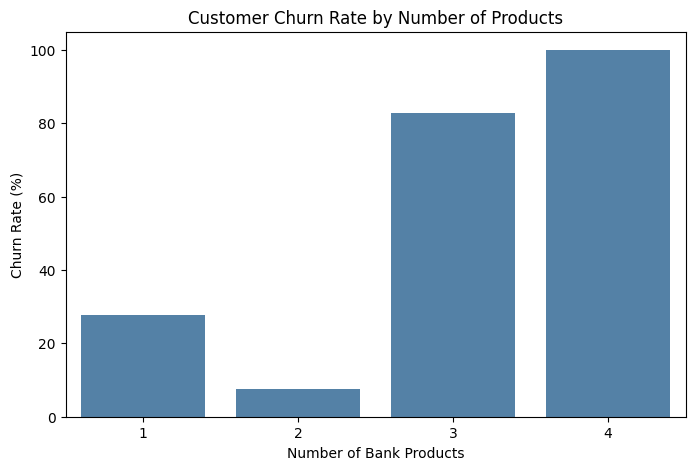

In [13]:
# Calculate churn rate by number of products
product_churn = df.groupby('products_number')['churn'].mean() * 100

# Display churn percentages
print(product_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=product_churn.index,
    y=product_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Number of Products')
plt.xlabel('Number of Bank Products')
plt.ylabel('Churn Rate (%)')

plt.show()

### 8. Customer Churn Analysis by Active Membership

active_member
0    26.85
1    14.27
Name: churn, dtype: float64


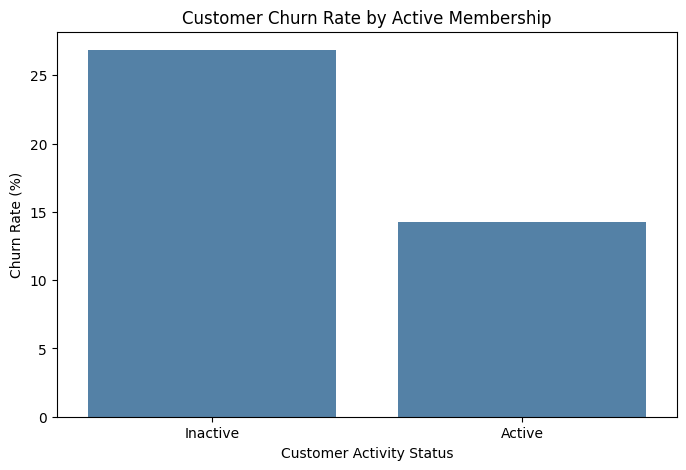

In [14]:
# Calculate churn rate by active membership
active_churn = df.groupby('active_member')['churn'].mean() * 100

# Display churn percentages
print(active_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=active_churn.index,
    y=active_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Active Membership')
plt.xlabel('Customer Activity Status')
plt.ylabel('Churn Rate (%)')

plt.xticks([0, 1], ['Inactive', 'Active'])

plt.show()

### 9. Customer Churn Analysis by Credit Score

credit_score_group
Below 500    23.73
500-599      21.23
600-699      19.72
700-799      19.90
800+         19.54
Name: churn, dtype: float64


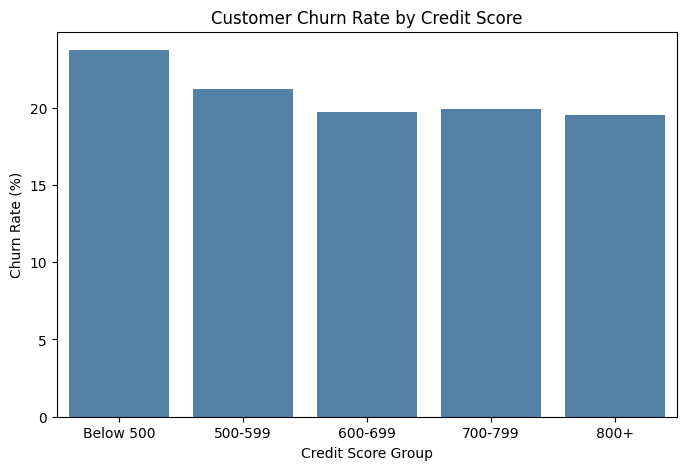

In [15]:
# Create credit score groups
df['credit_score_group'] = pd.cut(
    df['credit_score'],
    bins=[0, 500, 600, 700, 800, float('inf')],
    labels=['Below 500', '500-599', '600-699',
            '700-799', '800+'],
    right=False
)

# Calculate churn rate by credit score group
credit_churn = df.groupby(
    'credit_score_group', observed=True
)['churn'].mean() * 100

# Display churn percentages
print(credit_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=credit_churn.index,
    y=credit_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Credit Score')
plt.xlabel('Credit Score Group')
plt.ylabel('Churn Rate (%)')

plt.show()

### 10. Customer Churn Analysis by Tenure

tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: churn, dtype: float64


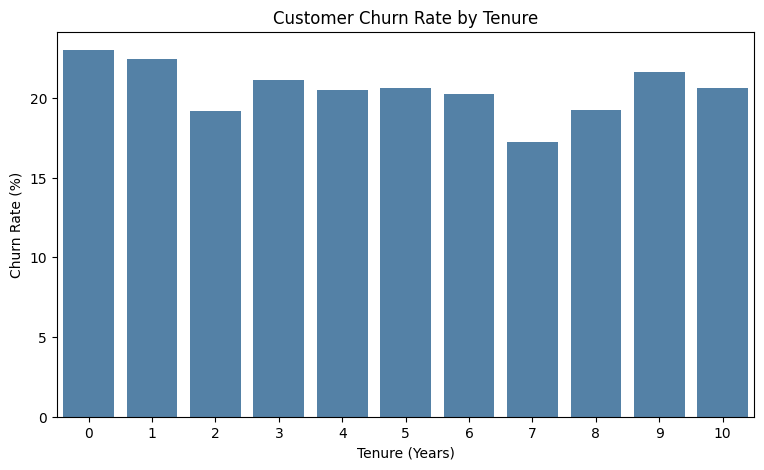

In [16]:
# Calculate churn rate by customer tenure
tenure_churn = df.groupby('tenure')['churn'].mean() * 100

# Display churn percentages
print(tenure_churn.round(2))

# Create visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Churn Rate (%)')

plt.show()

### 11. Customer Churn Analysis by Credit Card Ownership

credit_card
0    20.81
1    20.18
Name: churn, dtype: float64


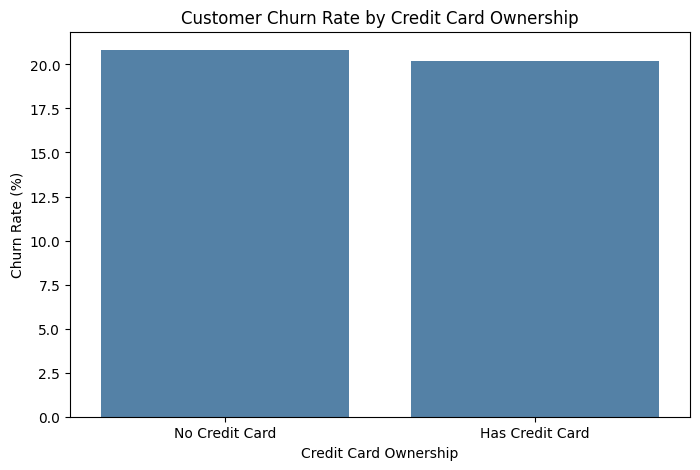

In [17]:
# Calculate churn rate by credit card ownership
credit_card_churn = df.groupby('credit_card')['churn'].mean() * 100

# Display churn percentages
print(credit_card_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=credit_card_churn.index,
    y=credit_card_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Credit Card Ownership')
plt.xlabel('Credit Card Ownership')
plt.ylabel('Churn Rate (%)')

plt.xticks([0, 1], ['No Credit Card', 'Has Credit Card'])

plt.show()

### 12. Customer Churn Analysis by Estimated Salary

salary_group
Below 50k    19.93
50k-99k      19.87
100k-149k    20.23
150k+        21.47
Name: churn, dtype: float64


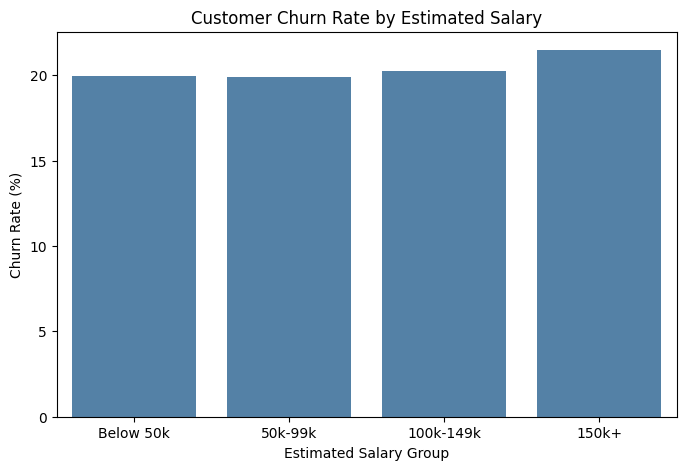

In [18]:
# Create estimated salary groups
df['salary_group'] = pd.cut(
    df['estimated_salary'],
    bins=[0, 50000, 100000, 150000, float('inf')],
    labels=['Below 50k', '50k-99k', '100k-149k', '150k+'],
    right=False
)

# Calculate churn rate by salary group
salary_churn = df.groupby(
    'salary_group', observed=True
)['churn'].mean() * 100

# Display churn percentages
print(salary_churn.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=salary_churn.index,
    y=salary_churn.values,
    color='steelblue'
)

plt.title('Customer Churn Rate by Estimated Salary')
plt.xlabel('Estimated Salary Group')
plt.ylabel('Churn Rate (%)')

plt.show()

## EDA Summary & Business Insights

### Key Findings

1. Overall Customer Churn:
   - Total customers: 10,000
   - Customers who left: 2,037
   - Overall churn rate: 20.37%

2. Customer Activity:
   - Inactive customers have a churn rate of 26.85%.
   - Active customers have a churn rate of 14.27%.
   - Inactive customers show higher churn.

3. Customer Age:
   - Customers aged 50–59 have the highest churn rate (56.04%).
   - Churn patterns vary considerably across age groups.

4. Geography:
   - Germany has the highest churn rate (32.44%).
   - France and Spain have much lower churn rates.

5. Banking Products:
   - Customers with 2 products have the lowest churn (7.58%).
   - Customers with 3 or 4 products show high churn,
     although these groups contain fewer customers.

6. Account Balance:
   - Customers with balances above 100,000 have a
     churn rate of 25.23%.

7. Credit Score, Salary and Tenure:
   - These variables show less consistent differences
     in churn across the groups examined.

8. Credit Card Ownership:
   - Churn rates are similar for customers with
     and without credit cards.

### Business Recommendations

1. Investigate why inactive customers leave the bank.

2. Review customer satisfaction and banking services
   in Germany.

3. Investigate dissatisfaction among customers
   holding multiple bank products.

4. Explore personalized customer engagement and
   retention strategies.

5. Develop a machine learning model to predict
   customer churn using multiple customer characteristics.

### Conclusion

The EDA indicates that customer activity, age groups,
geography, number of products and account balance are
associated with differences in customer churn.

These relationships do not establish causation.
Further modeling and validation are necessary.

The next stage is data preprocessing and building
a machine learning model to predict customer churn.

## Key Banking Insights
## Overall churn rate
20.37% -
2,037 out of 10,000 customers

## Highest churn by country
32.44% -
Germany

## Inactive customer churn
26.85% -
Compared with 14.27% for active customers

## Lowest churn by products
7.58% -
Customers holding two products

## Data Preprocessing

### 1. Check for Duplicate Records

In [19]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()

# Display the result
print("Number of Duplicate Records:", duplicate_count)

Number of Duplicate Records: 0


### 2. Remove Unnecessary Columns

In [20]:
# Select the columns needed for machine learning
model_columns = [
    'credit_score',
    'country',
    'gender',
    'age',
    'tenure',
    'balance',
    'products_number',
    'credit_card',
    'active_member',
    'estimated_salary',
    'churn'
]

# Create a separate dataset for machine learning
df_model = df[model_columns].copy()

# Check the new dataset shape
print("Dataset Shape:", df_model.shape)

# Display the first 5 rows
df_model.head()

Dataset Shape: (10000, 11)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### 3. Encoding Categorical Variables

In [21]:
# Convert categorical variables into numerical columns
df_encoded = pd.get_dummies(
    df_model,
    columns=['country', 'gender'],
    drop_first=True,
    dtype=int
)

# Check the new dataset shape
print("Dataset Shape After Encoding:", df_encoded.shape)

# Display the first 5 rows
df_encoded.head()

Dataset Shape After Encoding: (10000, 12)


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


### 4. Separate Features (X) and Target Variable (y)

In [22]:
# Separate input features and target variable

X = df_encoded.drop('churn', axis=1)

y = df_encoded['churn']

# Check the shapes
print("Features (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)

Features (X) Shape: (10000, 11)
Target (y) Shape: (10000,)


### 5. Split Dataset into Training and Testing Sets

In [23]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (8000, 11)
X_test Shape: (2000, 11)
y_train Shape: (8000,)
y_test Shape: (2000,)


### 6. Feature Scaling using StandardScaler

In [24]:
# Select numerical features for scaling
numeric_features = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'products_number',
    'estimated_salary'
]

# Initialize StandardScaler
scaler = StandardScaler()

# Create copies of training and testing data
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit and scale training data
X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

# Scale testing data using the same scaler
X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

# Display results
print("X_train_scaled Shape:", X_train_scaled.shape)
print("X_test_scaled Shape:", X_test_scaled.shape)

X_train_scaled.head()

X_train_scaled Shape: (8000, 11)
X_test_scaled Shape: (2000, 11)


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_Germany,country_Spain,gender_Male
2151,1.058568,1.715086,0.684723,-1.226059,-0.910256,1,0,1.042084,0,0,1
8392,0.913626,-0.659935,-0.696202,0.413288,-0.910256,1,0,-0.623556,1,0,1
5006,1.079274,-0.184931,-1.731895,0.601687,0.808830,1,1,0.308128,1,0,0
4117,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,1,0,-0.290199,0,0,1
7182,0.427035,0.955079,0.339492,0.548318,0.808830,0,1,0.135042,1,0,1


## Machine Learning Model Building

### A. Logistic Regression Model

In [25]:
# Initialize Logistic Regression model
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using training data
log_model.fit(X_train_scaled, y_train)

# Display confirmation message
print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


### Make Predictions Using Logistic Regression

In [26]:
# Make predictions using the trained model
y_pred_log = log_model.predict(X_test_scaled)

# Display the first 10 predictions
print("First 10 Predictions:")
print(y_pred_log[:10])

# Display total predictions
print("Total Predictions:", len(y_pred_log))

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]
Total Predictions: 2000


In [27]:
# Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual Churn': y_test.values,
    'Predicted Churn': y_pred_log
})

# Display first 10 records
comparison.head(10)

,Actual Churn,Predicted Churn
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [28]:
# Count predicted churn values
print("Prediction Distribution:")
print(pd.Series(y_pred_log).value_counts().sort_index())

Prediction Distribution:
0    1871
1     129
Name: count, dtype: int64


### Model Evaluation — Confusion Matrix

Confusion Matrix:
[[1540   53]
 [ 331   76]]


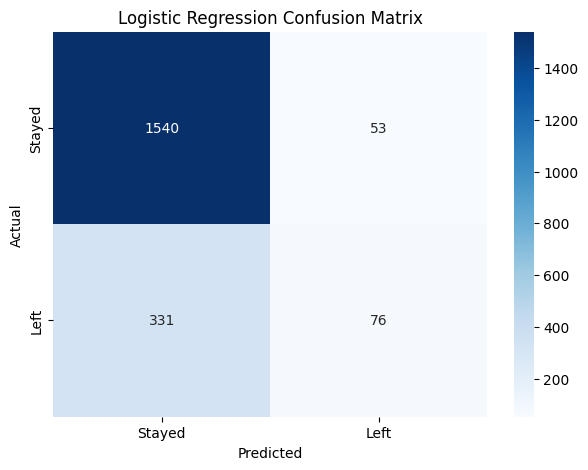

In [29]:
# Create Confusion Matrix
cm_log = confusion_matrix(y_test, y_pred_log)

# Display Confusion Matrix
print("Confusion Matrix:")
print(cm_log)

# Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Logistic Regression Performance Evaluation

In [30]:
# Calculate Logistic Regression performance

accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)

# Display evaluation results
print("Logistic Regression Performance:")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

Logistic Regression Performance:
Accuracy: 80.8 %
Precision: 58.91 %
Recall: 18.67 %
F1-Score: 28.36 %


### B. Random Forest Classifier

In [31]:
# Initialize Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train Random Forest model
rf_model.fit(X_train, y_train)

# Display confirmation message
print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


### Make Predictions Using Random Forest

In [32]:
# Make predictions using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Display first 10 predictions
print("First 10 Random Forest Predictions:")
print(y_pred_rf[:10])

# Display total predictions
print("Total Predictions:", len(y_pred_rf))

# Count predicted churn values
print("\nPrediction Distribution:")
print(pd.Series(y_pred_rf).value_counts().sort_index())

First 10 Random Forest Predictions:
[0 0 0 0 0 0 0 0 1 0]
Total Predictions: 2000

Prediction Distribution:
0    1770
1     230
Name: count, dtype: int64


### Random Forest Confusion Matrix

Random Forest Confusion Matrix:
[[1542   51]
 [ 228  179]]


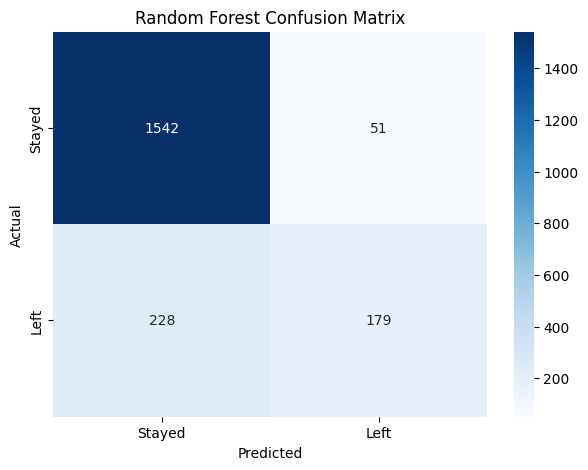

In [33]:
# Create Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Display Confusion Matrix
print("Random Forest Confusion Matrix:")
print(cm_rf)

# Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Random Forest Model Performance Evaluation

In [34]:
# Calculate Random Forest performance metrics

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

# Display results
print("Random Forest Performance:")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall:", round(rf_recall * 100, 2), "%")
print("F1-Score:", round(rf_f1 * 100, 2), "%")

Random Forest Performance:
Accuracy: 86.05 %
Precision: 77.83 %
Recall: 43.98 %
F1-Score: 56.2 %


### Machine Learning Model Comparison

In [35]:
# Compare Logistic Regression and Random Forest

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy (%)': [
        accuracy_score(y_test, y_pred_log) * 100,
        accuracy_score(y_test, y_pred_rf) * 100
    ],

    'Precision (%)': [
        precision_score(y_test, y_pred_log) * 100,
        precision_score(y_test, y_pred_rf) * 100
    ],

    'Recall (%)': [
        recall_score(y_test, y_pred_log) * 100,
        recall_score(y_test, y_pred_rf) * 100
    ],

    'F1-Score (%)': [
        f1_score(y_test, y_pred_log) * 100,
        f1_score(y_test, y_pred_rf) * 100
    ]
})

# Display comparison table
display(model_comparison.round(2))

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.80,58.91,18.67,28.36
1,Random Forest,86.05,77.83,43.98,56.20


### C. Gradient Boosting Classifier

In [36]:
# Import Gradient Boosting Classifier
from sklearn.ensemble import GradientBoostingClassifier

# Initialize Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Display confirmation
print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


### Gradient Boosting Model Evaluation

Gradient Boosting Model Performance
-----------------------------------
Accuracy:  87.00%
Precision: 79.28%
Recall:    48.89%
F1-Score:  60.49%

Confusion Matrix:
[[1541   52]
 [ 208  199]]


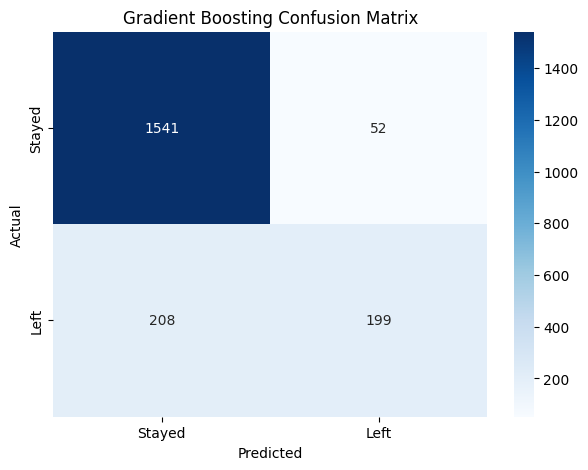

In [37]:
# Gradient Boosting - Predictions and Model Evaluation

# Step 1: Make predictions
y_pred_gb = gb_model.predict(X_test)

# Step 2: Calculate performance metrics
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb)
gb_recall = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)

# Step 3: Display performance metrics
print("Gradient Boosting Model Performance")
print("-----------------------------------")
print(f"Accuracy:  {gb_accuracy * 100:.2f}%")
print(f"Precision: {gb_precision * 100:.2f}%")
print(f"Recall:    {gb_recall * 100:.2f}%")
print(f"F1-Score:  {gb_f1 * 100:.2f}%")

# Step 4: Calculate Confusion Matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)

print("\nConfusion Matrix:")
print(cm_gb)

# Step 5: Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Gradient Boosting Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### XGBoost Classifier - Training and Evaluation

XGBoost Model Performance
-----------------------------------
Accuracy:  86.70%
Precision: 78.78%
Recall:    47.42%
F1-Score:  59.20%

Confusion Matrix:
[[1541   52]
 [ 214  193]]


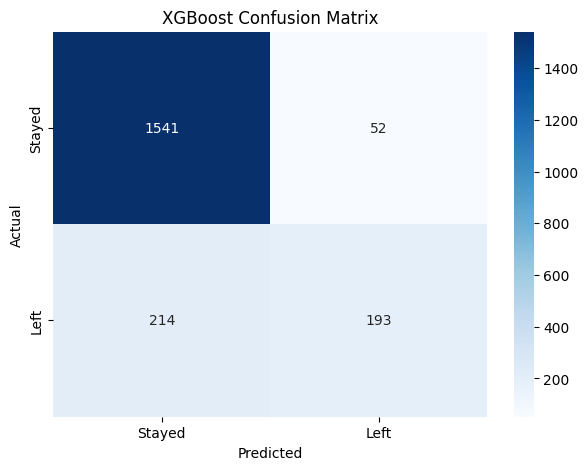

In [38]:
# Import XGBoost
try:
    from xgboost import XGBClassifier
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    from xgboost import XGBClassifier

# Step 1: Initialize XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)

# Step 2: Train the model
xgb_model.fit(X_train, y_train)

# Step 3: Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Step 4: Calculate performance metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)

# Step 5: Display results
print("XGBoost Model Performance")
print("-----------------------------------")
print(f"Accuracy:  {xgb_accuracy * 100:.2f}%")
print(f"Precision: {xgb_precision * 100:.2f}%")
print(f"Recall:    {xgb_recall * 100:.2f}%")
print(f"F1-Score:  {xgb_f1 * 100:.2f}%")

# Step 6: Calculate Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print("\nConfusion Matrix:")
print(cm_xgb)

# Step 7: Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Extra Trees Classifier - Training and Evaluation

Extra Trees Model Performance
-----------------------------------
Accuracy:  85.75%
Precision: 76.52%
Recall:    43.24%
F1-Score:  55.26%

Confusion Matrix:
[[1539   54]
 [ 231  176]]


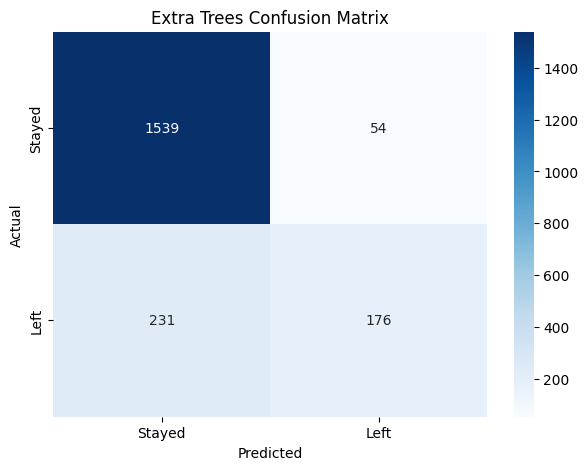

In [39]:

# Import Extra Trees Classifier
from sklearn.ensemble import ExtraTreesClassifier

# Step 1: Initialize model
et_model = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Step 2: Train model
et_model.fit(X_train, y_train)

# Step 3: Make predictions
y_pred_et = et_model.predict(X_test)

# Step 4: Calculate performance metrics
et_accuracy = accuracy_score(y_test, y_pred_et)
et_precision = precision_score(y_test, y_pred_et, zero_division=0)
et_recall = recall_score(y_test, y_pred_et)
et_f1 = f1_score(y_test, y_pred_et)

# Step 5: Display results
print("Extra Trees Model Performance")
print("-----------------------------------")
print(f"Accuracy:  {et_accuracy * 100:.2f}%")
print(f"Precision: {et_precision * 100:.2f}%")
print(f"Recall:    {et_recall * 100:.2f}%")
print(f"F1-Score:  {et_f1 * 100:.2f}%")

# Step 6: Calculate Confusion Matrix
cm_et = confusion_matrix(y_test, y_pred_et)

print("\nConfusion Matrix:")
print(cm_et)

# Step 7: Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_et,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Extra Trees Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


### Comparison of All Five Machine Learning Models

In [40]:
# Step 1: Store predictions from all five models
model_predictions = {
    'Logistic Regression': y_pred_log,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb,
    'XGBoost': y_pred_xgb,
    'Extra Trees': y_pred_et
}

# Step 2: Calculate performance metrics
results = []

for model_name, predictions in model_predictions.items():
    results.append({
        'Model': model_name,
        'Accuracy (%)': accuracy_score(y_test, predictions) * 100,
        'Precision (%)': precision_score(y_test, predictions) * 100,
        'Recall (%)': recall_score(y_test, predictions) * 100,
        'F1-Score (%)': f1_score(y_test, predictions) * 100
    })

# Step 3: Create comparison table
model_comparison = pd.DataFrame(results)
model_comparison = model_comparison.set_index('Model')

print("Machine Learning Model Comparison")
display(model_comparison.round(2))

Machine Learning Model Comparison


,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
Model,,,,
Logistic Regression,80.80,58.91,18.67,28.36
Random Forest,86.05,77.83,43.98,56.20
Gradient Boosting,87.00,79.28,48.89,60.49
XGBoost,86.70,78.78,47.42,59.20
Extra Trees,85.75,76.52,43.24,55.26


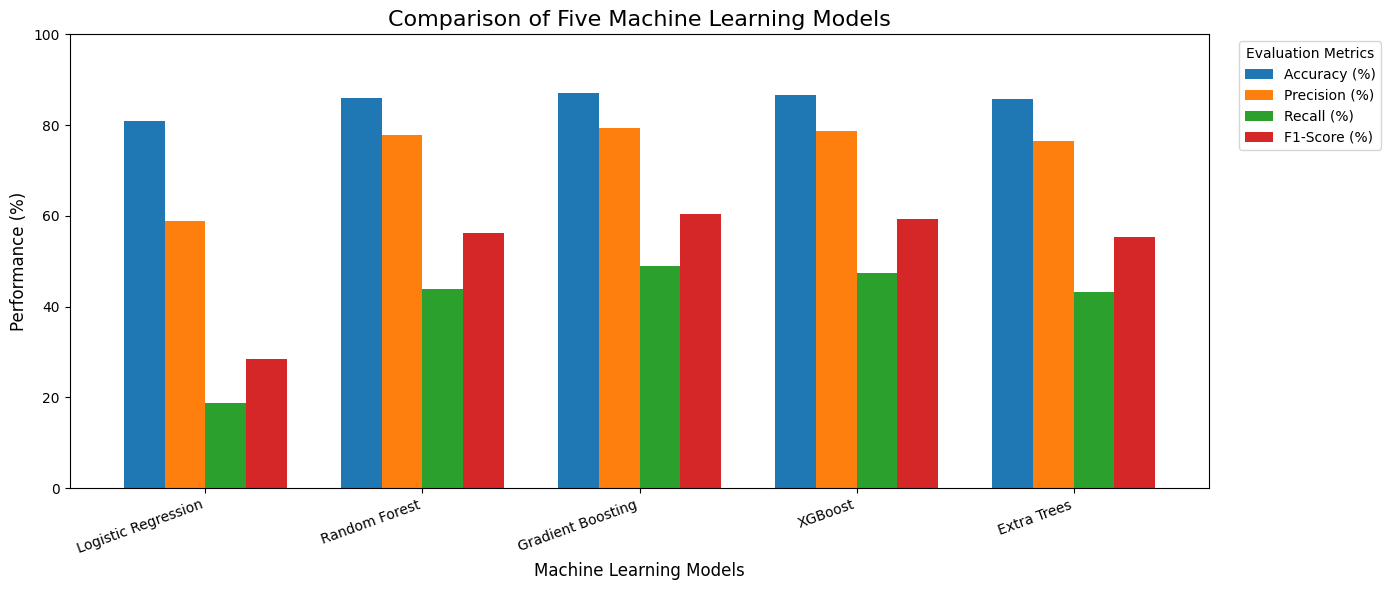

Highest Test F1-Score: Gradient Boosting


In [41]:
# Plot comparison chart separately
ax = model_comparison.plot(
    kind='bar',
    figsize=(14, 6),
    width=0.75
)

plt.title('Comparison of Five Machine Learning Models', fontsize=16)
plt.xlabel('Machine Learning Models', fontsize=12)
plt.ylabel('Performance (%)', fontsize=12)
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 100)
plt.legend(title='Evaluation Metrics', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Best model by F1-score
best_model = model_comparison['F1-Score (%)'].idxmax()
print("Highest Test F1-Score:", best_model)

### Gradient Boosting - Cross Validation

In [42]:

# Import Cross-Validation tools
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Gradient Boosting on training data
cv_results = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

# Display average performance
print("Gradient Boosting - 5-Fold Cross Validation")
print("------------------------------------------")

for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cv_results['test_' + metric]
    print(f"{metric.capitalize()}: {scores.mean()*100:.2f}%")

print("\nF1-Score for each fold:")
print((cv_results['test_f1'] * 100).round(2))


Gradient Boosting - 5-Fold Cross Validation
------------------------------------------
Accuracy: 86.31%
Precision: 77.22%
Recall: 46.44%
F1: 57.98%

F1-Score for each fold:
[58.71 62.12 61.25 55.47 52.34]


### Cross-Validation Comparison of All Five Models

In [43]:

# Import required tools
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression pipeline
# Scaling is fitted separately within each fold
log_cv_model = Pipeline([
    ('scaler', ColumnTransformer(
        [('num', StandardScaler(), numeric_features)],
        remainder='passthrough'
    )),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Store all five models
models = {
    'Logistic Regression': log_cv_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model,
    'XGBoost': xgb_model,
    'Extra Trees': et_model
}

# Perform cross-validation
cv_comparison_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1']
    )

    cv_comparison_results.append({
        'Model': name,
        'Accuracy (%)': scores['test_accuracy'].mean() * 100,
        'Precision (%)': scores['test_precision'].mean() * 100,
        'Recall (%)': scores['test_recall'].mean() * 100,
        'F1-Score (%)': scores['test_f1'].mean() * 100
    })

# Create comparison table
cv_comparison = pd.DataFrame(cv_comparison_results)

# Sort models by F1-Score
cv_comparison = cv_comparison.sort_values(
    by='F1-Score (%)',
    ascending=False
)

print("5-Fold Cross-Validation Model Comparison")
display(cv_comparison.round(2))


5-Fold Cross-Validation Model Comparison


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
2,Gradient Boosting,86.31,77.22,46.44,57.98
3,XGBoost,86.39,78.42,45.71,57.73
1,Random Forest,85.74,76.46,43.25,55.22
4,Extra Trees,85.20,72.91,43.44,54.41
0,Logistic Regression,81.04,59.61,21.35,31.41


### Gradient Boosting - Threshold Tuning

In [44]:

# Import required tools
from sklearn.model_selection import cross_val_predict

# Generate cross-validated churn probabilities
# Using training data only
cv_probabilities = cross_val_predict(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

# Test different classification thresholds
thresholds = [0.20, 0.25, 0.30, 0.35,
              0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    predictions = (cv_probabilities >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision (%)': precision_score(
            y_train, predictions, zero_division=0
        ) * 100,
        'Recall (%)': recall_score(
            y_train, predictions
        ) * 100,
        'F1-Score (%)': f1_score(
            y_train, predictions
        ) * 100
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

print("Gradient Boosting - Threshold Comparison")
display(threshold_df.round(2))

# Identify best threshold by F1-Score
best_threshold = threshold_df.loc[
    threshold_df['F1-Score (%)'].idxmax(),
    'Threshold'
]

print(f"\nBest Threshold by F1-Score: {best_threshold:.2f}")


Gradient Boosting - Threshold Comparison


,Threshold,Precision (%),Recall (%),F1-Score (%)
0,0.20,50.80,74.11,60.28
1,0.25,56.66,68.90,62.18
2,0.30,62.01,63.50,62.75
3,0.35,66.23,58.96,62.38
4,0.40,69.99,54.66,61.38
5,0.45,74.59,50.61,60.31
6,0.50,77.32,46.44,58.03



Best Threshold by F1-Score: 0.30


### Tuned Gradient Boosting - Model Evaluation

Tuned Gradient Boosting Performance
-----------------------------------
Threshold: 0.30
Accuracy:  85.30%
Precision: 63.48%
Recall:    65.36%
F1-Score:  64.41%

Confusion Matrix:
[[1440  153]
 [ 141  266]]


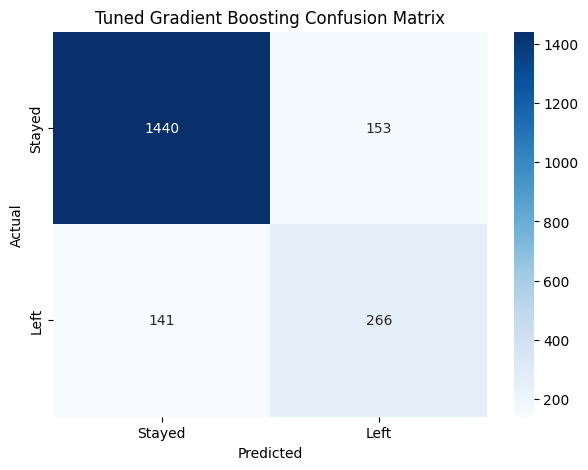

In [45]:

# Step 1: Predict churn probabilities
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Step 2: Apply selected threshold
y_pred_gb_tuned = (
    y_prob_gb >= best_threshold
).astype(int)

# Step 3: Calculate performance metrics
tuned_accuracy = accuracy_score(y_test, y_pred_gb_tuned)
tuned_precision = precision_score(y_test, y_pred_gb_tuned)
tuned_recall = recall_score(y_test, y_pred_gb_tuned)
tuned_f1 = f1_score(y_test, y_pred_gb_tuned)

# Step 4: Display results
print("Tuned Gradient Boosting Performance")
print("-----------------------------------")
print(f"Threshold: {best_threshold:.2f}")
print(f"Accuracy:  {tuned_accuracy * 100:.2f}%")
print(f"Precision: {tuned_precision * 100:.2f}%")
print(f"Recall:    {tuned_recall * 100:.2f}%")
print(f"F1-Score:  {tuned_f1 * 100:.2f}%")

# Step 5: Calculate Confusion Matrix
cm_gb_tuned = confusion_matrix(y_test, y_pred_gb_tuned)

print("\nConfusion Matrix:")
print(cm_gb_tuned)

# Step 6: Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Tuned Gradient Boosting Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


### Feature Importance Analysis

Gradient Boosting Feature Importance:


,Feature,Importance
1,age,0.3881
4,products_number,0.2999
6,active_member,0.1139
3,balance,0.0892
8,country_Germany,0.0556
0,credit_score,0.0187
7,estimated_salary,0.0165
10,gender_Male,0.0132
2,tenure,0.0038
5,credit_card,0.0007


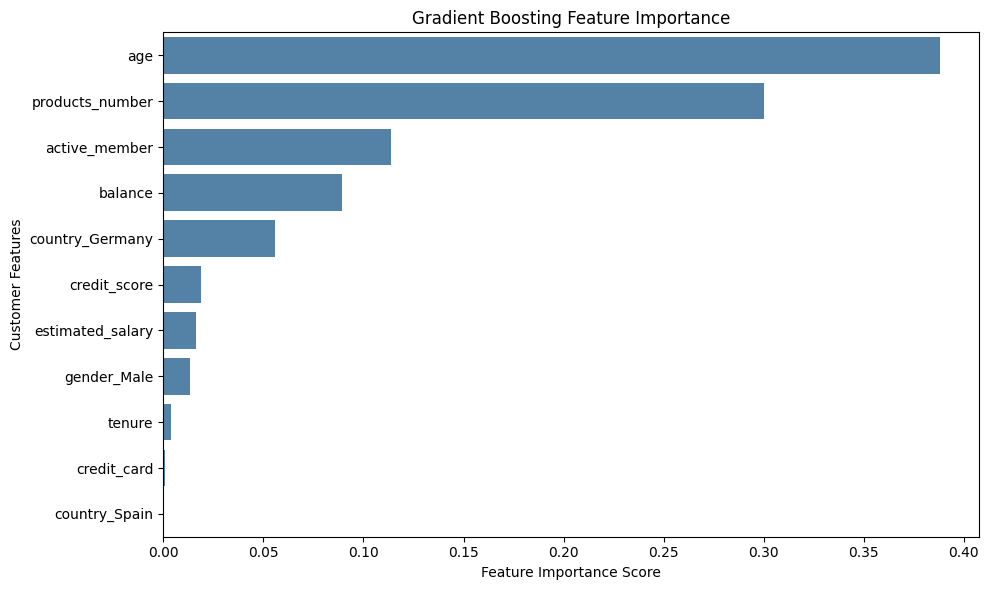

In [46]:

# Get feature importance from Gradient Boosting
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': gb_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance table
print("Gradient Boosting Feature Importance:")
display(feature_importance.round(4))

# Create visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Feature Importance Score')
plt.ylabel('Customer Features')

plt.tight_layout()
plt.show()


## Feature Importance & Business Insights

### Model Findings

1. Age is the most important feature in the
   Gradient Boosting model.

2. Number of banking products is the second
   most important feature.

3. Active membership and account balance
   also contribute to churn predictions.

4. Geography, particularly Germany,
   contributes to model predictions.

5. Credit score, salary, tenure, gender and
   credit card ownership have relatively
   lower importance in this model.

### Business Recommendations

1. Investigate customer satisfaction across
   different age groups.

2. Review customer experience for customers
   holding multiple banking products.

3. Develop and test customer engagement programs
   for inactive customers.

4. Investigate customer retention challenges
   in Germany.

5. Use machine learning predictions to support
   customer retention analysis, with appropriate
   fairness and privacy checks.

### Final Model Findings (Preliminary)

Selected Candidate: Gradient Boosting

Classification Threshold: 0.30

Accuracy: 85.30%
Precision: 63.48%
Recall: 65.36%
F1-Score: 64.41%

These results are exploratory test-set results.
An independent final evaluation is still needed.

### Conclusion

Gradient Boosting is our current preferred model
for predicting bank customer churn.

Threshold tuning improved Recall and F1-Score,
allowing the model to identify more customers
who actually left the bank.

Feature importance helps us understand which
customer characteristics influence predictions,
but does not establish causal relationships.

## Save the Trained Machine Learning Model

### Save Gradient Boosting Model

In [47]:

# Import required libraries
import joblib
from google.colab import files

# Create a model package
model_bundle = {
    'model': gb_model,
    'threshold': float(best_threshold),
    'feature_columns': X_train.columns.tolist(),
    'raw_feature_columns': df_model.drop(
        columns='churn'
    ).columns.tolist(),
    'country_categories': ['France', 'Germany', 'Spain'],
    'gender_categories': ['Female', 'Male']
}

# Save the model package
model_filename = 'bank_customer_churn_model.pkl'

joblib.dump(model_bundle, model_filename)

# Display confirmation
print("Machine Learning Model Saved Successfully!")
print("File Name:", model_filename)
print("Selected Threshold:", model_bundle['threshold'])

# Download model to your computer
files.download(model_filename)


Machine Learning Model Saved Successfully!
File Name: bank_customer_churn_model.pkl
Selected Threshold: 0.3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Load and Test the Saved Model

In [48]:

# Step 1: Load the saved model package
import joblib
import numpy as np

loaded_bundle = joblib.load(
    'bank_customer_churn_model.pkl'
)

# Step 2: Extract model and threshold
loaded_model = loaded_bundle['model']
loaded_threshold = loaded_bundle['threshold']
loaded_columns = loaded_bundle['feature_columns']

# Step 3: Align test data with saved feature order
X_test_loaded = X_test[loaded_columns]

# Step 4: Make predictions using the loaded model
loaded_probabilities = loaded_model.predict_proba(
    X_test_loaded
)[:, 1]

loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

# Step 5: Compare with original tuned predictions
predictions_match = np.array_equal(
    loaded_predictions,
    y_pred_gb_tuned
)

print("Saved Model Loaded Successfully!")
print("Classification Threshold:", loaded_threshold)
print("Total Predictions:", len(loaded_predictions))
print("Predictions Match Original Model:", predictions_match)


Saved Model Loaded Successfully!
Classification Threshold: 0.3
Total Predictions: 2000
Predictions Match Original Model: True


### Predict Customer Churn for a New Customer

In [49]:

# Step 1: Enter new customer details
new_customer = pd.DataFrame([{
    'credit_score': 650,
    'country': 'Germany',
    'gender': 'Female',
    'age': 45,
    'tenure': 5,
    'balance': 100000,
    'products_number': 1,
    'credit_card': 1,
    'active_member': 0,
    'estimated_salary': 60000
}])

# Step 2: Apply the same encoding used during training
new_customer['country'] = pd.Categorical(
    new_customer['country'],
    categories=loaded_bundle['country_categories']
)

new_customer['gender'] = pd.Categorical(
    new_customer['gender'],
    categories=loaded_bundle['gender_categories']
)

new_customer_encoded = pd.get_dummies(
    new_customer,
    columns=['country', 'gender'],
    drop_first=True,
    dtype=int
)

# Step 3: Match the training feature columns and order
new_customer_encoded = new_customer_encoded.reindex(
    columns=loaded_bundle['feature_columns'],
    fill_value=0
)

# Step 4: Predict churn probability
churn_probability = loaded_model.predict_proba(
    new_customer_encoded
)[0][1]

# Step 5: Apply our tuned classification threshold
prediction = int(
    churn_probability >= loaded_threshold
)

# Step 6: Display prediction results
print("BANK CUSTOMER CHURN PREDICTION")
print("-----------------------------------")
print(f"Churn Probability: {churn_probability * 100:.2f}%")
print(f"Classification Threshold: {loaded_threshold:.2f}")

if prediction == 1:
    print("Prediction: Customer Likely to Leave")
else:
    print("Prediction: Customer Likely to Stay")


BANK CUSTOMER CHURN PREDICTION
-----------------------------------
Churn Probability: 76.55%
Classification Threshold: 0.30
Prediction: Customer Likely to Leave


In [50]:

# Step 1: Define the base customer profile
base_customer = {
    'credit_score': 650,
    'country': 'Germany',
    'gender': 'Female',
    'age': 45,
    'tenure': 5,
    'balance': 100000,
    'products_number': 1,
    'credit_card': 1,
    'active_member': 0,
    'estimated_salary': 60000
}

# Step 2: Create three customer scenarios
scenarios = []

for name, active, products in [
    ('Inactive - 1 Product', 0, 1),
    ('Active - 1 Product', 1, 1),
    ('Active - 2 Products', 1, 2)
]:
    customer = base_customer.copy()
    customer['active_member'] = active
    customer['products_number'] = products
    customer['Scenario'] = name
    scenarios.append(customer)

scenario_df = pd.DataFrame(scenarios)

# Step 3: Prepare input for the model
scenario_input = scenario_df.drop(
    columns=['Scenario']
).copy()

# Apply the same categorical encoding as training
for column, category_key in [
    ('country', 'country_categories'),
    ('gender', 'gender_categories')
]:
    scenario_input[column] = pd.Categorical(
        scenario_input[column],
        categories=loaded_bundle[category_key]
    )

scenario_encoded = pd.get_dummies(
    scenario_input,
    columns=['country', 'gender'],
    drop_first=True,
    dtype=int
)

# Match the trained model's feature columns
scenario_encoded = scenario_encoded.reindex(
    columns=loaded_bundle['feature_columns'],
    fill_value=0
)

# Step 4: Predict churn probabilities
probabilities = loaded_model.predict_proba(
    scenario_encoded
)[:, 1]

predictions = (
    probabilities >= loaded_threshold
).astype(int)

# Step 5: Display comparison results
scenario_results = pd.DataFrame({
    'Customer Scenario': scenario_df['Scenario'],
    'Churn Probability (%)': (probabilities * 100).round(2),
    'Prediction': [
        'Likely to Leave' if p == 1 else 'Likely to Stay'
        for p in predictions
    ]
})

print("CUSTOMER CHURN SCENARIO COMPARISON")
print("Classification Threshold:", loaded_threshold)

display(scenario_results)


CUSTOMER CHURN SCENARIO COMPARISON
Classification Threshold: 0.3


,Customer Scenario,Churn Probability (%),Prediction
0,Inactive - 1 Product,76.55,Likely to Leave
1,Active - 1 Product,51.51,Likely to Leave
2,Active - 2 Products,27.99,Likely to Stay


## Streamlit Application

In [51]:
# Upload Streamlit application and trained model
from google.colab import files

uploaded = files.upload()

Saving app.py to app.py
Saving bank_customer_churn_model.pkl to bank_customer_churn_model (1).pkl


In [52]:
import os

print("Streamlit App:", os.path.exists("app.py"))
print("Trained Model:", os.path.exists("bank_customer_churn_model.pkl"))

Streamlit App: True
Trained Model: True


### Install and Launch Streamlit

In [53]:
# Install Streamlit
!pip install -q streamlit

print("Streamlit Installed Successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 55.7 MB/s eta 0:00:00
Streamlit Installed Successfully!


In [56]:

# Create requirements.txt for Streamlit deployment

from importlib.metadata import version
from google.colab import files
import sys

packages = [
    'streamlit',
    'pandas',
    'numpy',
    'scikit-learn',
    'joblib'
]

with open('requirements.txt', 'w') as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

print("requirements.txt created successfully!")
print("Python Version:", sys.version.split()[0])

print("\nInstalled Dependencies:")
with open('requirements.txt', 'r') as f:
    print(f.read())

# Download requirements.txt
files.download('requirements.txt')


requirements.txt created successfully!
Python Version: 3.13.16

Installed Dependencies:
streamlit==1.66.1
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
joblib==1.6.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>